In [1]:

import pandas as pd

# Create Web Traffic Dataset

data = {
    'Date': ['2026-01-01', '2026-01-02', '2026-01-03',
             '2026-01-04', '2026-01-05', '2026-01-06',
             '2026-01-07', '2026-01-08', '2026-01-09',
             '2026-01-10'],

    'Visitors': [120, 150, 180, 100, 200, 250, 220, 300, 280, 350],

    'PageViews': [300, 400, 450, 250, 500, 600, 550, 700, 650, 800],

    'TrafficSource': ['Google', 'Direct', 'Social Media',
                      'Google', 'Direct', 'Google',
                      'Social Media', 'Google', 'Direct', 'Social Media'],

    'Device': ['Mobile', 'Desktop', 'Mobile', 'Tablet',
               'Desktop', 'Mobile', 'Desktop', 'Mobile',
               'Tablet', 'Desktop'],

    'BounceRate': [45, 40, 50, 55, 35, 30, 42, 28, 38, 25]
}

df = pd.DataFrame(data)

# Display dataset
print(df)


         Date  Visitors  PageViews TrafficSource   Device  BounceRate
0  2026-01-01       120        300        Google   Mobile          45
1  2026-01-02       150        400        Direct  Desktop          40
2  2026-01-03       180        450  Social Media   Mobile          50
3  2026-01-04       100        250        Google   Tablet          55
4  2026-01-05       200        500        Direct  Desktop          35
5  2026-01-06       250        600        Google   Mobile          30
6  2026-01-07       220        550  Social Media  Desktop          42
7  2026-01-08       300        700        Google   Mobile          28
8  2026-01-09       280        650        Direct   Tablet          38
9  2026-01-10       350        800  Social Media  Desktop          25


In [2]:

# 1. Display first 5 records
print("First 5 Records:")
print(df.head())

# 2. Dataset information
print("\nDataset Information:")
print(df.info())

# 3. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 5. Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

print("\nDate column converted successfully!")

# 6. Display final data types
print("\nFinal Data Types:")
print(df.dtypes)


First 5 Records:
         Date  Visitors  PageViews TrafficSource   Device  BounceRate
0  2026-01-01       120        300        Google   Mobile          45
1  2026-01-02       150        400        Direct  Desktop          40
2  2026-01-03       180        450  Social Media   Mobile          50
3  2026-01-04       100        250        Google   Tablet          55
4  2026-01-05       200        500        Direct  Desktop          35

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Date           10 non-null     object
 1   Visitors       10 non-null     int64 
 2   PageViews      10 non-null     int64 
 3   TrafficSource  10 non-null     object
 4   Device         10 non-null     object
 5   BounceRate     10 non-null     int64 
dtypes: int64(3), object(3)
memory usage: 612.0+ bytes
None

Missing Values:
Date             0


In [3]:

# Web Traffic Analysis

print("WEB TRAFFIC ANALYSIS")
print("----------------------")

# Total Visitors
print("Total Visitors:", df['Visitors'].sum())

# Total Page Views
print("Total Page Views:", df['PageViews'].sum())

# Average Visitors
print("Average Visitors:", df['Visitors'].mean())

# Average Page Views
print("Average Page Views:", df['PageViews'].mean())

# Average Bounce Rate
print("Average Bounce Rate:", df['BounceRate'].mean(), "%")

# Maximum Visitors
print("Maximum Visitors:", df['Visitors'].max())

# Minimum Visitors
print("Minimum Visitors:", df['Visitors'].min())


WEB TRAFFIC ANALYSIS
----------------------
Total Visitors: 2150
Total Page Views: 5200
Average Visitors: 215.0
Average Page Views: 520.0
Average Bounce Rate: 38.8 %
Maximum Visitors: 350
Minimum Visitors: 100


In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


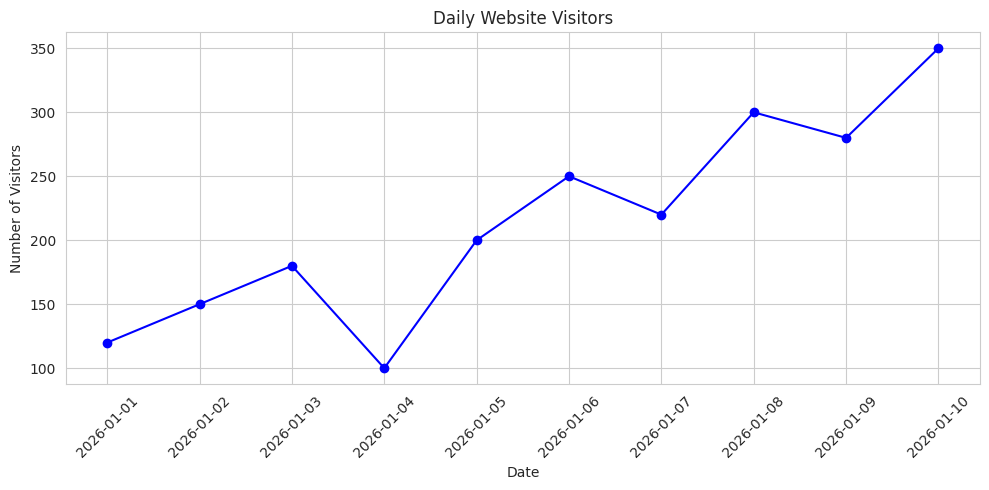

In [15]:

plt.figure(figsize=(10,5))

plt.plot(df['Date'], df['Visitors'],
         marker='o', color='blue')

plt.title('Daily Website Visitors')
plt.xlabel('Date')
plt.ylabel('Number of Visitors')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


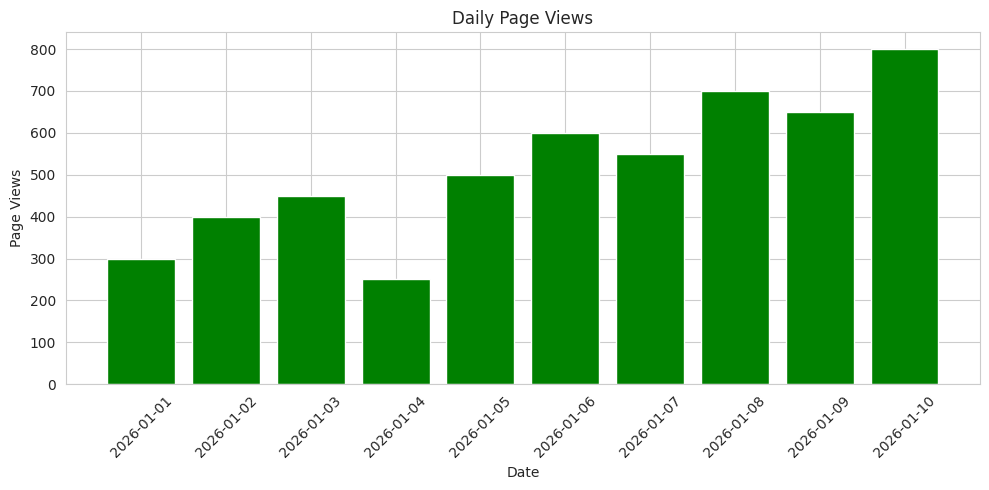

In [16]:

plt.figure(figsize=(10,5))

plt.bar(df['Date'], df['PageViews'], color='green')

plt.title('Daily Page Views')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


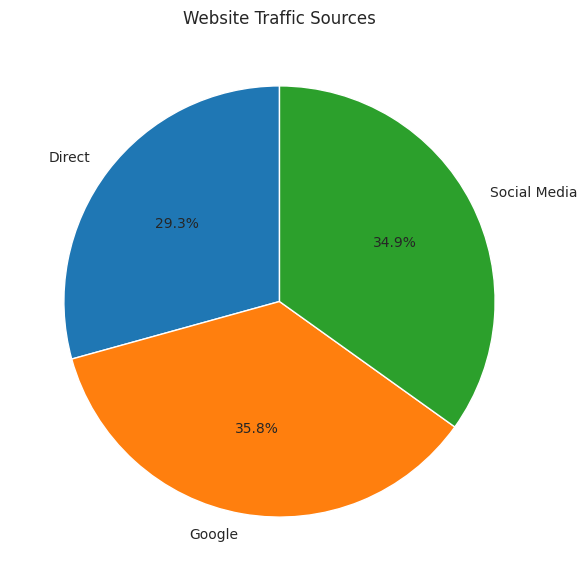

In [17]:

traffic = df.groupby('TrafficSource')['Visitors'].sum()

plt.figure(figsize=(7,7))

plt.pie(traffic, labels=traffic.index,
        autopct='%1.1f%%', startangle=90)

plt.title('Website Traffic Sources')
plt.show()


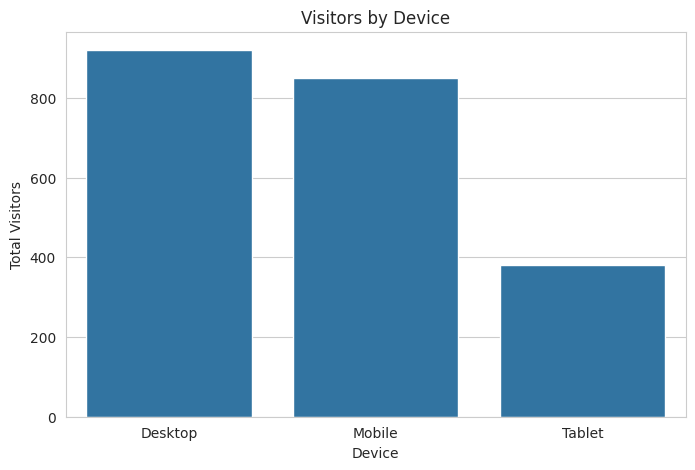

In [18]:

device = df.groupby('Device')['Visitors'].sum()

plt.figure(figsize=(8,5))

sns.barplot(x=device.index, y=device.values)

plt.title('Visitors by Device')
plt.xlabel('Device')
plt.ylabel('Total Visitors')

plt.show()


In [19]:

# 1. Visitors by Traffic Source
print("VISITORS BY TRAFFIC SOURCE")
print(df.groupby('TrafficSource')['Visitors'].sum())

# 2. Visitors by Device
print("\nVISITORS BY DEVICE")
print(df.groupby('Device')['Visitors'].sum())

# 3. Highest Traffic Date
highest = df.loc[df['Visitors'].idxmax()]
print("\nHIGHEST TRAFFIC DATE")
print(highest['Date'], "-", highest['Visitors'], "visitors")

# 4. Lowest Traffic Date
lowest = df.loc[df['Visitors'].idxmin()]
print("\nLOWEST TRAFFIC DATE")
print(lowest['Date'], "-", lowest['Visitors'], "visitors")

# 5. Average Bounce Rate by Device
print("\nAVERAGE BOUNCE RATE BY DEVICE")
print(df.groupby('Device')['BounceRate'].mean())


VISITORS BY TRAFFIC SOURCE
TrafficSource
Direct          630
Google          770
Social Media    750
Name: Visitors, dtype: int64

VISITORS BY DEVICE
Device
Desktop    920
Mobile     850
Tablet     380
Name: Visitors, dtype: int64

HIGHEST TRAFFIC DATE
2026-01-10 00:00:00 - 350 visitors

LOWEST TRAFFIC DATE
2026-01-04 00:00:00 - 100 visitors

AVERAGE BOUNCE RATE BY DEVICE
Device
Desktop    35.50
Mobile     38.25
Tablet     46.50
Name: BounceRate, dtype: float64


In [20]:

print("PROJECT CONCLUSION")
print("===================")

print("1. Google is the leading traffic source.")
print("2. Desktop is the most used device.")
print("3. Highest visitors: 350 on 10 January 2026.")
print("4. Lowest visitors: 100 on 4 January 2026.")
print("5. Tablet users have the highest bounce rate.")
print("6. Total website visitors:", df['Visitors'].sum())

print("\nWeb Traffic Analytics Project Completed!")


PROJECT CONCLUSION
1. Google is the leading traffic source.
2. Desktop is the most used device.
3. Highest visitors: 350 on 10 January 2026.
4. Lowest visitors: 100 on 4 January 2026.
5. Tablet users have the highest bounce rate.
6. Total website visitors: 2150

Web Traffic Analytics Project Completed!


In [21]:

# Save dataset as CSV

df.to_csv('web_traffic_data.csv', index=False)

# Download CSV file
from google.colab import files
files.download('web_traffic_data.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>